# pbsolve tutorial

pbsolve computes electrostatic potentials and polar solvation energies of
biomolecules from the linearized Poisson–Boltzmann equation, on the CPU or on
NVIDIA GPUs. By default it reproduces APBS (`mg-auto`); faster or more accurate
methods are options you switch on explicitly.

This notebook goes from installation to MM-PBSA and a comparison with APBS.
Run it from top to bottom: every section needs only the **Setup** cell and,
from section 4 on, the 1YCR structure loaded there. Timings depend on the
machine (and on other jobs running on it); energies do not.

**Tutorial changelog.** Each pbsolve change that affects users updates the
sections listed here; the date under every section heading says when it last
changed.

| Date | pbsolve change | Sections |
|---|---|---|
| 2026-11-06 | First version. `multigrid-f32` is the default preconditioner; faster host stages with bit-identical results; optional `bcfl="mdh-fast"` | all |
| 2026-11-06 | CUDA builds the multigrid hierarchy on the GPU: setup 2–3× faster, results bit-identical | 7, 14 |
| 2026-11-06 | CUDA also builds the dielectric and ion maps, the operator and the right-hand side on the GPU: a calculation ~1.2× faster, results bit-identical | 7, 14 |
| 2026-11-06 | Batches on CUDA run only as many calculations at once as fit in the free GPU memory (`Solver.batch_workers`): large grids no longer run out of memory | 11, 14 |
| 2026-11-07 | Energies read the potential only at the charges and where the next focusing level needs it, instead of copying the whole grid: CUDA 1.06–1.10× faster, results bit-identical | 7, 8, 14 |
| 2026-11-07 | On CUDA a calculation keeps the GPU memory it frees between focusing levels and returns it to the driver when it ends: the solve stage 1.05–1.10× faster, results bit-identical | 7 |
| 2026-11-08 | The exact `mdh` sums use AVX2, and on CUDA the CPU computes the solvated state's boundary while the GPU solves the reference state: a CUDA calculation 1.21–1.25× faster, the CPU boundary ~1.2×, results bit-identical | 6, 7 |
| 2026-11-08 | On CUDA the solvated state's first level also builds its maps, operator and multigrid before its boundary is ready: `mdh` calculations 1.05–1.06× faster, results bit-identical | 7 |
| 2026-11-08 | Every class, function and parameter is documented: `help()` and the API reference of the documentation site show the same text | 14 |
| 2026-11-09 | A user guide explains the settings and tools topic by topic; its examples run in the test suite | 14 |
| 2026-11-09 | The multigrid smoother computes each step in one pass: calculations 1.17–1.25× faster on the CPU, the CUDA solve stage 1.17–1.26×, results bit-identical | 5, 7 |
| 2026-11-10 | The conjugate-gradient updates and dot products run in fewer passes over memory: a CPU calculation 1.03–1.07× faster, results bit-identical | 5, 14 |
| 2026-11-10 | Comparison with APBS on three larger proteins (up to 20 179 atoms); the binding verdict of `pbsolve apbs compare` judges ΔΔG in APBS units | 12 |
| 2026-11-11 | `pbsolve.analytic.kirkwood_energy`: the exact energy of charges anywhere inside a sphere, with or without salt; averaged over grid placements the error falls in proportion to the spacing | 3 |
| 2026-11-13 | `pbsolve.analytic.two_sphere_energy`: the same for two spheres; their association energy on one grid is far more accurate than the energies themselves | 3 |
| 2026-11-14 | `chgm="spl2"` and `"spl4"`: B-spline charge assignment as in APBS, which `pbsolve apbs` now compares and replays; timings of the fused steps on an idle GPU | 12, 14 |
| 2026-11-14 | `pbsolve.estimate_error`: ΔG_polar over several grid placements, with its spread and an extrapolation to zero spacing | 4 |
| 2026-11-14 | `interface="fractional"`: faces cut by the molecular surface get a harmonic average weighted by the exact cut of their grid edge; energies close to second order and 5–10 times less dependent on the grid placement | 3, 4, 14 |
| 2026-11-14 | `coulomb="analytic"`: reaction-field decomposition, ΔG_polar without a reference state from one solve per level; with the fractional interface half the placement spread | 4, 14 |
| 2026-11-14 | `equation="npbe"`: the nonlinear Poisson–Boltzmann equation as APBS `npbe`, with its free-energy functional; `pbsolve apbs` compares it | 4, 12, 14 |
| 2026-11-15 | `equation="smpbe"` with `ion_size`: the nonlinear equation for ions of finite size (lattice gas), which keep counterions below one per lattice cell | 4, 12, 14 |
| 2026-11-15 | `Solver.polar_forces` and APBS' spline surfaces `surface="spl2"`/`"spl4"`: forces on the atoms as APBS `calcforce`; `pbsolve apbs compare --forces` | 4, 12, 14 |
| 2026-11-15 | `surface="gauss"`: the Gaussian dielectric, graded by the atoms' densities instead of a surface, with ions kept out by their Born energy | 4, 14 |
| 2026-11-15 | `apolar_energy`: the non-polar model of APBS `apolar` (surface, volume and dispersion), equal to APBS' alkane examples | 11, 14 |
| 2026-11-15 | Per-atom and per-residue shares of the solvation terms (`atom_energies`, `PBSAFrame.residue_terms`, `pbsolve mmpbsa --per-residue`) | 11 |
| 2026-11-15 | `interaction_entropy` and `interaction_energy`: −TΔS of binding from the fluctuations of the interaction energy (IE and C2) | 11, 14 |
| 2026-11-15 | `dielectrics=`: an interior dielectric per atom (`residue_dielectrics`, `--residue-dielectric`) and `PBSAFrame.delta_reference` | 4, 14 |

**Contents**
1. Installation
2. Checking the installation
3. First calculation: the Born ion
4. A protein complex: MDM2–p53 (1YCR)
5. Linear solvers and preconditioners
6. Boundary conditions: `mdh` (APBS) and `mdh-fast`
7. CPU and GPU
8. Electrostatic potential maps
9. Reading simulation files and selecting atoms
10. Preparing a PDB file
11. MM-PBSA solvation terms
12. Checking against APBS
13. Command line
14. Further reading

To re-run the whole notebook and store its outputs:
`jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.record_timing=False examples/pbsolve_tutorial.ipynb`

## 1. Installation
_Last updated: 2026-11-06 (commit 7f2f939)._

pbsolve is built from source for now (a conda-forge package is planned). You
need conda (Miniforge) and, for the GPU, an NVIDIA driver; the CUDA toolkit is
**not** needed, because pbsolve compiles its GPU kernels at runtime with NVRTC.

```bash
git clone https://github.com/Bio-Otto/pbsolve.git
cd pbsolve
conda create -n pbsolve -c conda-forge python=3.12 rust maturin numpy pytest
conda activate pbsolve

# CPU only
maturin develop --release

# CPU + CUDA: pick the feature that matches the driver's CUDA major version
# (nvidia-smi shows it) and install NVRTC of the same major version
conda install -c conda-forge "cuda-nvrtc>=13,<14"
maturin develop --release --features cuda-13      # or cuda-12 with cuda-nvrtc 12
```

Optional packages used in this notebook and by some features:

```bash
conda install -c conda-forge jupyterlab matplotlib   # this notebook
conda install -c conda-forge apbs                    # section 12, comparison with APBS
pip install pdb2pqr propka                           # reference preparation, PROPKA protonation
conda install -c conda-forge openmm                  # OpenMM bridge (examples/mmpbsa_openmm.py)
```

Without a usable GPU, `platform="auto"` simply runs on the CPU.

## Setup
_Last updated: 2026-11-06 (commit 7f2f939)._

Imports, the test structures that ship with the repository (`tests/data`), an
output folder, and two helpers: `cli` runs the `pbsolve` command line of this
Python environment, and `show` prints a table.

In [1]:
import os
import shutil
import subprocess
import sys
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

import pbsolve

here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / "tests" / "data" / "1ycr.pdb").exists()), None)
assert ROOT is not None, "run this notebook from inside the pbsolve repository"
DATA = Path(os.path.relpath(ROOT / "tests" / "data"))
PQR = DATA / "1ycr_amber_opt_pdb2pqr.pqr"  # MDM2–p53 complex, pdb2pqr 3 --ff=AMBER
OUT = Path("tutorial_output")
OUT.mkdir(exist_ok=True)


def cli(*args):
    """Run `python -m pbsolve ARGS` and print its output."""
    run = subprocess.run([sys.executable, "-m", "pbsolve", *map(str, args)], capture_output=True, text=True)
    print((run.stdout + run.stderr).rstrip())


def show(rows, header):
    """Display rows as a Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


print("pbsolve", pbsolve.__version__, "| platforms:", ", ".join(pbsolve.available_platforms()))

pbsolve 0.0.5 | platforms: CUDA, CPU


## 2. Checking the installation
_Last updated: 2026-11-06 (commit 7f2f939)._

`pbsolve info` reports the build and whether CUDA is usable (and if not, why).
`pbsolve test` solves a Born ion on every available platform, compares it with
the analytic energy and checks that the platforms agree with each other.

In [2]:
cli("info")

pbsolve 0.0.5
platforms: CUDA, CPU
cuda.compiled: True
cuda.cuda_major: 13
cuda.available: True
cuda.device_count: 1
cuda.reason: None
cuda.driver: 13.2
cuda.nvrtc: 13.2
cuda.nvrtc_library: /home/bio-otto/miniforge3/envs/pbsolve-apbs/targets/x86_64-linux/lib/libnvrtc.so.13.2.86


In [3]:
cli("test")

pbsolve version: 0.0.5
CUDA support compiled: True (CUDA 13)
CUDA available: True
CUDA driver 13.2, NVRTC 13.2 (/home/bio-otto/miniforge3/envs/pbsolve-apbs/targets/x86_64-linux/lib/libnvrtc.so.13.2.86)
Testing platforms: CUDA, CPU

 CUDA: ok         ΔG =  -82.9970 kcal/mol (analytic -81.9589, error -1.27%), 18 CG iterations, 0.03 s on NVIDIA GeForce RTX 2080 SUPER (cc 7.5, device 0)
  CPU: ok         ΔG =  -82.9970 kcal/mol (analytic -81.9589, error -1.27%), 18 CG iterations, 0.10 s on CPU (18 threads)

Platform agreement:
  CUDA vs CPU: relative difference 0.00e+00 ok

All tests passed.


The same information is available from Python:

In [4]:
info = pbsolve.cuda_info()
print("CUDA compiled in:", info["compiled"], "| usable:", info["available"])
print("NVRTC:", info["nvrtc_library"] if info["available"] else info["reason"])

CUDA compiled in: True | usable: True
NVRTC: /home/bio-otto/miniforge3/envs/pbsolve-apbs/targets/x86_64-linux/lib/libnvrtc.so.13.2.86


## 3. First calculation: the Born ion
_Last updated: 2026-11-14 (fractional interface)._

A unit charge in a sphere of radius *a* = 2 Å, moved from vacuum (ε = 1) into
water (ε = 78.54), has the solvation energy
ΔG = −(*l*<sub>B</sub>/2*a*)(1 − 1/78.54) kT, where *l*<sub>B</sub> is the
Bjerrum length in vacuum. Coordinates, charges and radii are numpy arrays
in Å, e and Å; energies are in kcal/mol.

In [5]:
from pbsolve.test_installation import born_energy

ion = dict(coords=np.array([[0.1, -0.05, 0.02]]), charges=np.array([1.0]), radii=np.array([2.0]))
exact = born_energy(radius=2.0)
rows = []
for h in [0.5, 0.35, 0.25, 0.2]:
    res = pbsolve.Solver(grid_spacing=h, fadd=12.0).polar_solvation(**ion)
    error = 100 * (res.energy - exact) / abs(exact)
    rows.append([h, f"{res.grid.fine_spacing[0]:.3f}", f"{res.energy:.3f}", f"{error:+.2f} %", sum(res.iterations)])
print(f"analytic: {exact:.3f} kcal/mol")
show(rows, ["requested h (Å)", "fine grid h (Å)", "ΔG (kcal/mol)", "error", "CG iterations"])

analytic: -81.959 kcal/mol


| requested h (Å) | fine grid h (Å) | ΔG (kcal/mol) | error | CG iterations |
|---|---|---|---|---|
| 0.5 | 0.500 | -85.833 | -4.73 % | 16 |
| 0.35 | 0.333 | -82.847 | -1.08 % | 17 |
| 0.25 | 0.250 | -82.997 | -1.27 % | 18 |
| 0.2 | 0.200 | -82.731 | -0.94 % | 17 |

`grid_spacing` is an upper bound: the automatic grid rounds the number of
nodes per axis up to 8k + 1, so the actual spacing can be smaller. The error is about 1 % once
h ≤ 1/3 Å, but it does not shrink monotonically:
with a sharp dielectric boundary the result depends on where the sphere's
surface falls between grid nodes. `docs/VALIDATION.md` lists the same
numbers. The number of CG iterations hardly grows as the grid gets finer;
that is the multigrid preconditioner (section 5).

Charges away from the centre of a sphere have an exact solution too
[Kirkwood 1934], with or without salt: `pbsolve.analytic.kirkwood_energy`.
In pbsolve the sphere is one atom of radius *a* without charge, and the
charges are atoms of radius 0 inside it; ions stay beyond *a* + `ion_radius`
in both.

In [6]:
from pbsolve.analytic import kirkwood_energy

a = 5.0
pos = np.array([[2.0, 0.0, 0.0], [-1.0, 2.0, 0.5], [0.5, -1.0, -2.5]])
q = np.array([1.0, -1.0, 0.5])
exact = kirkwood_energy(pos, q, a, ionic_strength=0.15)
sphere = dict(coords=np.vstack([[0.0, 0.0, 0.0], pos]), charges=np.r_[0.0, q], radii=np.r_[a, 0.0, 0.0, 0.0])
rows = []
for interface in ["sharp", "fractional"]:
    for h in [0.5, 0.25]:
        res = pbsolve.Solver(grid_spacing=h, ionic_strength=0.15, interface=interface).polar_solvation(**sphere)
        rows.append([interface, h, f"{res.energy:.3f}", f"{100 * (res.energy - exact) / abs(exact):+.2f} %"])
print(f"Kirkwood: {exact:.3f} kcal/mol")
show(rows, ["interface", "h (Å)", "ΔG (kcal/mol)", "error"])

Kirkwood: -37.337 kcal/mol


| interface | h (Å) | ΔG (kcal/mol) | error |
|---|---|---|---|
| sharp | 0.5 | -38.529 | -3.19 % |
| sharp | 0.25 | -37.790 | -1.21 % |
| fractional | 0.5 | -37.357 | -0.05 % |
| fractional | 0.25 | -37.286 | +0.14 % |

Averaged over many placements of the molecule on the grid, the error of
both tests falls in proportion to the spacing: the method is first order,
as expected for a sharp dielectric boundary. `interface="fractional"` gives
the faces that the surface cuts the harmonic average of the two dielectric
constants, weighted by how much of the face's grid edge lies inside the
solute. Its errors are at least 5 times smaller at 0.5 Å and fall about as h².
With the default `mol` surface they level off near +0.15 %: APBS' sampled
probe positions leave tiny cusps on the sphere, and the fractional faces
resolve them. `scripts/validate_analytic.py` measures all this;
`docs/VALIDATION.md` has the tables.

`pbsolve.analytic.two_sphere_energy` gives the energy of charges in two
spheres. Their association energy (the pair minus each sphere alone, all on
the pair's grid, as in MM-PBSA) comes out far more accurately than the
energies themselves: within 0.002 kcal/mol with `surface="vdw"` and about
0.015 kcal/mol with the default `mol`, whose sampled probe positions leave
tiny cusps on the spheres.

## 4. A protein complex: MDM2–p53 (1YCR)
_Last updated: 2026-11-15 (atom dielectrics)._

`tests/data/1ycr_amber_opt_pdb2pqr.pqr` is the MDM2 domain (chain A) with the
p53 peptide (chain B), prepared by pdb2pqr with AMBER charges and radii.
`read_pqr` returns coordinates, charges and radii as numpy arrays.

`Solver` holds the settings; the defaults follow APBS: ε 1 inside, 78.54
outside, a molecular surface with a 1.4 Å probe, `bcfl="mdh"`, automatic
focusing grids with spacing ≤ 0.5 Å. `ionic_strength` is in mol/L.

In [7]:
coords, charges, radii = pbsolve.read_pqr(PQR)
print(f"{len(charges)} atoms, net charge {charges.sum():+.2f} e")

solver = pbsolve.Solver(ionic_strength=0.15)  # platform="auto": CUDA if usable, else CPU
res = solver.polar_solvation(coords, charges, radii)
print(f"ΔG_polar = {res.energy:.4f} kcal/mol on {res.platform}")
print("grid:", res.grid.dims, "nodes, fine spacing", np.round(res.grid.fine_spacing, 3), "Å")
print("CG iterations per linear solve:", res.iterations)
print("preconditioner:", res.preconditioners[0], "with", res.levels[0], "multigrid levels")
show([[stage, f"{t:.3f}"] for stage, t in res.timings.items()], ["stage", "seconds"])

1670 atoms, net charge +3.00 e


ΔG_polar = -1231.3481 kcal/mol on CUDA
grid: [121, 121, 105] nodes, fine spacing [0.486 0.492 0.472] Å
CG iterations per linear solve: [12, 12, 8, 8]
preconditioner: multigrid-f32 with 5 multigrid levels


| stage | seconds |
|---|---|
| assembly | 0.006 |
| boundary | 0.047 |
| energy | 0.001 |
| maps | 0.025 |
| setup | 0.044 |
| solve | 0.098 |
| total | 0.220 |

ΔG_polar is the difference between two electrostatic energies: the solvated
state (ε 78.54 outside the molecule, salt) and the reference state (ε 1
everywhere, no salt). Each state is solved on two focusing grids, so there
are four linear solves. The timing table shows where the time goes: building
the coefficient maps, the boundary values, assembling the system, the
multigrid setup, the solve and the energy.

**How much does the grid matter?** ΔG_polar depends on the spacing and on
where the molecular surface falls between the grid nodes.
`pbsolve.estimate_error` solves on several placements of the grid (the first
is the grid above) and reports their mean, spread (sd) and the standard
error of the mean; given two spacings, it also extrapolates the mean to zero
spacing. Four placements at 0.5 Å:

In [8]:
est = pbsolve.estimate_error(solver, coords, charges, radii, placements=4)
print(est.format())
print(f"first placement {est.energies[0]:.4f} kcal/mol = ΔG_polar above")

-1234.120 ± 2.770 kcal/mol (mean ± sem of 4 placements; sd 5.541) at h = 0.484 Å
first placement -1231.3481 kcal/mol = ΔG_polar above


Single placements differ by a few kcal/mol here. The spacing itself matters
more: averaged over placements, ΔG_polar of this complex is −1234.7,
−1205.6 and −1190.5 kcal/mol at 0.48, 0.34 and 0.25 Å, and extrapolates to
about −1152 kcal/mol (`docs/VALIDATION.md`, *Error estimates*). Compare
energies only between calculations with the same grid settings, as MM-PBSA
does with its three species on one grid.

**A more accurate boundary.** With `interface="fractional"` the same four
placements:

In [9]:
fractional = pbsolve.Solver(ionic_strength=0.15, interface="fractional")
est_f = pbsolve.estimate_error(fractional, coords, charges, radii, placements=4)
print(est_f.format())

-1165.222 ± 0.570 kcal/mol (mean ± sem of 4 placements; sd 1.140) at h = 0.484 Å


The placements now agree to about a kcal/mol, and the mean at 0.5 Å is
much closer to the zero-spacing limit, about −1155.6 kcal/mol
(`docs/VALIDATION.md`, *Reaction-field decomposition*).
For MM-PBSA this matters most: ΔΔG_polar of binding is off by about
+13 kcal/mol at 0.5 Å with the default faces and by +2.7 with fractional
ones. The default stays `"sharp"` because it reproduces APBS exactly.

**Without a reference state.** By default ΔG_polar is the difference of two
solves on the same grid, so that each charge's self-energy on the grid
cancels. `coulomb="analytic"` subtracts the analytic Coulomb potential near
the solute instead and solves only for the reaction field, once per
focusing level (reaction-field decomposition, `docs/guide/model.md`):


In [10]:
decomposed = pbsolve.Solver(ionic_strength=0.15, interface="fractional", coulomb="analytic")
est_d = pbsolve.estimate_error(decomposed, coords, charges, radii, placements=4)
print(est_d.format())


-1161.153 ± 0.334 kcal/mol (mean ± sem of 4 placements; sd 0.668) at h = 0.484 Å


The placements spread less (sd 0.67 instead of 1.14 kcal/mol), and the mean
lies 4 kcal/mol closer to the zero-spacing limit, with one solve per level
instead of two. On the CPU that makes a calculation 1.7 times faster. With
the default sharp faces the decomposition changes little, because their own
error dominates. It is not an APBS option either; `docs/VALIDATION.md`,
*Reaction-field decomposition*, derives it and relates it to the literature.


**Nonlinear Poisson–Boltzmann.** The default linearized equation lets the
ions respond in proportion to the potential. `equation="npbe"` (APBS `npbe`)
uses the Boltzmann distribution instead, which matters where the potential
exceeds about 1 kT/e at the ions. `equation="smpbe"` also gives the ions a
size: each fills a cube of edge `ion_size` (here 6 Å), so they cannot crowd
beyond one per cube. 1YCR against a strongly charged sphere (−30 e,
radius 4 Å):


In [11]:
sphere = (np.array([[0.11, -0.07, 0.05]]), np.array([-30.0]), np.array([4.0]))
rows = []
for name, (x, q, r), salt in [("1YCR", (coords, charges, radii), 0.15), ("-30 e sphere", sphere, 0.1)]:
    res = {eq: pbsolve.Solver(ionic_strength=salt, equation=eq, ion_size=6.0 if eq == "smpbe" else 0.0).polar_solvation(x, q, r)
           for eq in ["lpbe", "npbe", "smpbe"]}
    e = {eq: res[eq].energy for eq in res}
    rows.append([name, f"{e['lpbe']:.3f}", f"{e['npbe']:.3f}", f"{e['npbe'] - e['lpbe']:+.3f}", f"{e['smpbe'] - e['npbe']:+.3f}"])
show(rows, ["molecule", "lpbe (kcal/mol)", "npbe (kcal/mol)", "npbe − lpbe", "smpbe − npbe (6 Å ions)"])


| molecule | lpbe (kcal/mol) | npbe (kcal/mol) | npbe − lpbe | smpbe − npbe (6 Å ions) |
|---|---|---|---|---|
| 1YCR | -1231.348 | -1231.377 | -0.029 | +0.007 |
| -30 e sphere | -37559.560 | -37657.056 | -97.496 | +55.458 |

For the protein the two equations differ by a few hundredths of a kcal/mol;
at the sphere the linearized potential at the ions is −22 kT/e, the
nonlinear one −7.5, and ΔG_polar differs by about 100 kcal/mol. The
nonlinear energy is APBS' free-energy functional and matches APBS `npbe`
(section 12). For strongly charged molecules, enlarge `cfac` and `fadd`: the
functional misses the field energy beyond the outermost box
(`docs/guide/model.md`, *Nonlinear equation*).

Finite ion size always costs free energy, little for the protein and more at
the sphere, where the counterions crowd. There is no single right size
(published fits use 2–16 Å), and APBS 3.4.1 disables its `smpbe`; pbsolve's
is checked against exact planar double layers and published scaling laws
(`docs/VALIDATION.md`, *Size-modified PB*).


**Forces on the atoms.** `polar_forces` computes −dΔG_polar/dr on every atom
(kcal/mol/Å), as APBS `calcforce`. It needs a boundary that moves smoothly with
the atoms: APBS' spline surface `surface="spl2"`, where the dielectric rises
from 1 to 78.54 over ±`swin` = 0.3 Å around each atomic sphere. The force has
three parts: the reaction field at the charges (`qf`), the field's pressure on
the dielectric boundary (`db`) and the ions' pressure on the ion-accessibility
boundary (`ib`). The five atoms with the largest forces:


In [12]:
smooth = pbsolve.Solver(ionic_strength=0.15, surface="spl2", chgm="spl2")
f = smooth.polar_forces(coords, charges, radii)
norm = lambda v: np.linalg.norm(v, axis=1)
rows = [[int(n), f"{charges[n]:+.3f}", f"{radii[n]:.2f}", *(f"{norm(part)[n]:.2f}" for part in (f.qf, f.db, f.ib, f.forces))]
        for n in np.argsort(-norm(f.forces))[:5]]
show(rows, ["atom", "charge (e)", "radius (Å)", "qf", "db", "ib", "total (magnitudes, kcal/mol/Å)"])
print(f"ΔG_polar: {f.energy:.1f} kcal/mol with spl2, {est.energies[0]:.1f} with the molecular surface")


| atom | charge (e) | radius (Å) | qf | db | ib | total (magnitudes, kcal/mol/Å) |
|---|---|---|---|---|---|---|
| 414 | -0.676 | 1.72 | 19.80 | 72.02 | 0.00 | 87.92 |
| 1100 | +0.427 | 0.00 | 78.70 | 0.00 | 0.00 | 78.70 |
| 22 | -0.676 | 1.72 | 28.13 | 53.16 | 0.00 | 76.74 |
| 1358 | +0.399 | 0.00 | 73.52 | 0.00 | 0.00 | 73.52 |
| 1349 | -0.558 | 1.72 | 28.83 | 39.94 | 0.00 | 66.79 |

ΔG_polar: -2578.3 kcal/mol with spl2, -1231.3 with the molecular surface


Two of these atoms are hydroxyl hydrogens with radius 0 (AMBER): they do not
shape the boundary, so their force is all charge–field. The forces are the
exact derivative of the energy pbsolve computes (on one grid, to 4e-9) and
agree with APBS 3.4.1 to a few parts in 10⁷ (section 12).
The spline surface is a different model: without a probe, crevices count as
solvent, so ΔG_polar is about twice as large as with the molecular surface.
The boundary part is also sensitive to where the molecule sits on the grid.
`docs/VALIDATION.md` (*Spline surfaces and forces*) has the details and a
check against Kirkwood's analytic force on a charge in a sphere.


**A Gaussian dielectric.** `surface="gauss"` has no surface at all. Every
atom is a Gaussian density of width `gauss_sigma` (0.93) times its radius,
and the dielectric follows the molecule's density: nearly `pdie` where atoms
are densely packed, intermediate in loose packing and grooves, `sdie` in the
solvent (Li et al. 2013). The ions pay the Born energy of entering a lower
dielectric. ΔG_polar and ΔΔG_polar of binding on the complex's grid:


In [13]:
peptide = pbsolve.io.load(PQR).select("chain B")
species = {"complex": np.ones(len(charges), bool), "MDM2": ~peptide, "peptide": peptide}
rows = []
for label, kw in [("mol, pdie 1", {}), ("gauss, pdie 1", dict(surface="gauss")), ("gauss, pdie 4", dict(surface="gauss", pdie=4.0))]:
    s = pbsolve.Solver(ionic_strength=0.15, **kw)
    grid = s.make_grid(coords, radii)  # one grid for all three species
    e = {name: s.polar_solvation(coords[m], charges[m], radii[m], grid=grid).energy for name, m in species.items()}
    rows.append([label, f"{e['complex']:.1f}", f"{e['complex'] - e['MDM2'] - e['peptide']:.1f}"])
show(rows, ["model", "ΔG_polar of the complex (kcal/mol)", "ΔΔG_polar of binding (kcal/mol)"])


| model | ΔG_polar of the complex (kcal/mol) | ΔΔG_polar of binding (kcal/mol) |
|---|---|---|
| mol, pdie 1 | -1231.3 | 423.7 |
| gauss, pdie 1 | -985.8 | 400.7 |
| gauss, pdie 4 | -450.5 | 116.9 |

The reference state of ΔG_polar keeps the Gaussian dielectric wherever it is
at most `gauss_contour` (20) and removes only the solvent beyond (Li et al.
2014). With a uniform `pdie` reference, as for the other surfaces, the
charges' own grid self-energies would not cancel: ε rises within a few tenths
of an Å of every nucleus, and ΔG_polar would run from −39 000 to −61 000
kcal/mol between 0.5 and 0.25 Å. With the contour, ΔΔG_polar of binding
changes by about 2 kcal/mol between 0.5 and 0.25 Å (with these radii and
with mbondi2 radii; `mol` with mbondi2 radii: 7). `docs/VALIDATION.md`,
*Gaussian dielectric*, has the numbers and a check of one Gaussian atom
against its exact solution. The AMBER hydrogens of radius 0 carry no
density; their charges lie inside the contour, which pbsolve checks. The
Gaussian dielectric works with `lpbe` and `smpbe`, not with `npbe`, forces or
`coulomb="analytic"`.


**A dielectric per atom.** `dielectrics` gives every atom its own interior
dielectric, as DelPhi's multiple dielectrics: a face inside the surface takes
the value of the atom whose power cell (smallest |x − c|² − R²) contains it,
and the reference state keeps this interior with `pdie` outside.
`residue_dielectrics` gives charged residues one value and the rest another
(Liu, Peng & Zhang 2019 fitted 2.7 and 1.1 for MM/GBSA). For binding,
`pbsa_solvation_frame` also reports `delta_reference`, the receptor–ligand
interaction in the reference state: the Coulomb energy over `pdie` for one
`pdie`, the interaction with the interior dielectrics otherwise. It takes
the place of the force field's Coulomb term, and `delta_reference +
delta_polar` is the electrostatic binding energy in water:

In [14]:
mol = pbsolve.io.load(PQR)
labels = [f"{c}:{n}:{i}" for c, n, i in zip(mol.chains, mol.resnames, mol.resids)]
ligand = np.nonzero(peptide)[0]
rows = []
for label, pdie, eps in [
    ("pdie 1", 1.0, None),
    ("pdie 4", 4.0, None),
    ("charged 4, other 1", 1.0, pbsolve.residue_dielectrics(charges, labels, charged=4.0, neutral=1.0)),
    ("charged 2.7, other 1.1", 1.0, pbsolve.residue_dielectrics(charges, labels, charged=2.7, neutral=1.1)),
]:
    s = pbsolve.Solver(ionic_strength=0.15, pdie=pdie)
    f = pbsolve.pbsa_solvation_frame(s, coords, charges, radii, ligand, dielectrics=eps)
    rows.append([label, f"{f.delta_reference:.1f}", f"{f.delta_polar:.1f}", f"{f.delta_reference + f.delta_polar:.1f}"])
show(rows, ["interior", "ΔE_ref (kcal/mol)", "ΔΔG_polar", "sum"])

| interior | ΔE_ref (kcal/mol) | ΔΔG_polar | sum |
|---|---|---|---|
| pdie 1 | -361.4 | 423.7 | 62.3 |
| pdie 4 | -90.4 | 102.4 | 12.1 |
| charged 4, other 1 | -386.0 | 421.5 | 35.5 |
| charged 2.7, other 1.1 | -378.6 | 417.7 | 39.1 |

The residue dielectrics hardly change ΔΔG_polar: the reference medium
outside the protein is still vacuum. They change the interaction in that
reference state (charged residues of ε 4 in vacuum) and the electrostatic
sum, which does not depend on the reference at all: 36 instead of 62
kcal/mol (with `pdie=4` everywhere: 12). With every value equal to `pdie`
the result is exactly that of `pdie`. pbsolve is checked against the exact
solutions for one and two spheres with their own interiors
(`docs/VALIDATION.md`, *Atom dielectrics*). The option needs `surface="mol"`
or `"vdw"`, the sharp interface and `coulomb="grid"`.

## 5. Linear solvers and preconditioners
_Last updated: 2026-11-10 (fused CG steps)._

pbsolve solves each linear system with conjugate gradients (CG) to a relative
residual of `tol=1e-8`. The preconditioner decides how many iterations that
takes:

* `"multigrid-f32"` (default): a multigrid V-cycle computed in single
  precision inside the double-precision CG. Same energies as `"multigrid"`
  to ~1e-13, faster because it moves half the data.
* `"multigrid"`: the same V-cycle in double precision.
* `"jacobi"`: diagonal scaling, as a baseline; it needs dozens of times more
  iterations.

The V-cycle smooths every grid level with a Chebyshev polynomial. pbsolve
computes each smoothing step in one pass over memory (one kernel on the GPU)
with the same arithmetic as the individual operations, so the results do not
change, but the CPU solves 1.2–1.3× faster and the GPU 1.2–1.3× faster in
this stage. The vector updates and dot products of the CG iteration are
combined in the same way, which makes a CPU calculation another 1.03–1.07×
faster.

In [15]:
rows, ref = [], None
for pre in ["multigrid-f32", "multigrid", "jacobi"]:
    r = pbsolve.Solver(ionic_strength=0.15, preconditioner=pre).polar_solvation(coords, charges, radii)
    ref = r.energy if ref is None else ref
    rows.append([pre, f"{r.energy:.6f}", f"{abs(r.energy - ref) / abs(ref):.1e}", sum(r.iterations), f"{r.timings['solve']:.2f}"])
show(rows, ["preconditioner", "ΔG (kcal/mol)", "rel. diff. to default", "CG iterations", "solve (s)"])

| preconditioner | ΔG (kcal/mol) | rel. diff. to default | CG iterations | solve (s) |
|---|---|---|---|---|
| multigrid-f32 | -1231.348136 | 0.0e+00 | 40 | 0.11 |
| multigrid | -1231.348136 | 6.3e-14 | 40 | 0.15 |
| jacobi | -1231.348109 | 2.2e-08 | 1506 | 1.28 |

The two multigrid variants agree to rounding. Jacobi differs at the 1e-8
level, which is the solver tolerance: every preconditioner solves the same
equations, but the iterations stop at a slightly different point.

## 6. Boundary conditions: `mdh` (APBS) and `mdh-fast`
_Last updated: 2026-11-08 (`mdh` sums vectorised)._

The potential on the outer face of the coarsest grid comes from an analytic
approximation (`bcfl`):

* `"mdh"` (default): the sum of the Debye–Hückel potentials of all atoms at
  every boundary node, evaluated exactly as APBS does. Its cost grows with
  atoms × boundary nodes. On CPUs with AVX2 it handles four boundary nodes
  per instruction, with the same rounding.
* `"mdh-fast"` (pbsolve only): the same sum, computed exactly only at
  Chebyshev points of patches of the box faces and interpolated in between.
  The interpolation error is at most 1e-10 of the summed terms, so energies
  agree with `"mdh"` to ~1e-13. Inputs written for APBS use `mdh`.
* `"sdh"` (one sphere with charge, dipole and quadrupole) and `"zero"` are
  cheaper physical approximations; they change the result.

In [16]:
rows = []
for bc in ["mdh", "mdh-fast", "sdh", "zero"]:
    r = pbsolve.Solver(ionic_strength=0.15, bcfl=bc).polar_solvation(coords, charges, radii)
    ref = r.energy if bc == "mdh" else ref
    rows.append([bc, f"{r.energy:.6f}", f"{abs(r.energy - ref) / abs(ref):.1e}", f"{r.timings['boundary']:.3f}"])
show(rows, ["bcfl", "ΔG (kcal/mol)", "rel. diff. to mdh", "boundary (s)"])

| bcfl | ΔG (kcal/mol) | rel. diff. to mdh | boundary (s) |
|---|---|---|---|
| mdh | -1231.348136 | 0.0e+00 | 0.036 |
| mdh-fast | -1231.348136 | 7.0e-14 | 0.026 |
| sdh | -1229.942247 | 1.1e-03 | 0.010 |
| zero | -1182.590625 | 4.0e-02 | 0.015 |

For a 1670-atom complex the boundary is cheap either way. It matters for
large proteins and long trajectories; measured in `docs/VALIDATION.md`
(boundary time per ΔG_polar, CPU):

| System | Atoms | `mdh` | `mdh-fast` | rel. ΔG difference |
|---|---|---|---|---|
| 1YCR | 1 670 | 0.052 s | 0.038 s | 1.1e-13 |
| 1TII | 10 862 | 0.77 s | 0.18 s | 7.5e-15 |
| 5DK3 | 20 179 | 2.91 s | 0.37 s | 3.1e-15 |

On CUDA most of this time is hidden (section 7). Use `"mdh"` when results
must match APBS operation for operation, and `"mdh-fast"` for large systems
or many frames.

## 7. CPU and GPU
_Last updated: 2026-11-08 (solvated setup before its boundary)._

The same algorithm runs on every platform, and the results agree to rounding
(about 1e-13). On CUDA most of the preparation runs on the GPU as well, with the
CPU's operation order, so every intermediate result is identical to the CPU's
bit for bit:
* the dielectric and ion maps (the solute, probe and ion-exclusion spheres are
  marked on the device; the surface points are still found on the host);
* the operator, the charges on the grid and the right-hand side;
* the multigrid hierarchy (only its coarsest level, ≤ 1000 unknowns, is
  factorised on the host);
* the potential itself: a solvation energy needs it only at the grid nodes
  around the charges, and the next focusing level only around its boundary,
  so only those values are copied back to the host.

A calculation also keeps the GPU memory it frees between focusing levels, so
the next level does not have to request it from the driver again; the memory
goes back to the driver when the calculation ends.

The analytic boundary (section 6) and the surface points stay on the CPU.
pbsolve solves the reference state first, and while the GPU works on it the
CPU computes the solvated state's surface and boundary. The GPU then builds
the solvated state's maps, operator and multigrid, which do not need the
boundary, and waits for it only before the right-hand side. So on CUDA
`timings["boundary"]` counts only the time the GPU had to wait.

The table lists the time of each stage: `maps`, `assembly` (operator and
right-hand side), `setup` (multigrid) and the total. The first CUDA calculation in a process also creates the GPU
context, so it is timed separately here. If no GPU is usable, this cell says
why.

In [17]:
if "CUDA" in pbsolve.available_platforms():
    rows = []
    for platform in ["cpu", "cuda"]:
        s = pbsolve.Solver(platform=platform, ionic_strength=0.15)
        s.polar_solvation(coords, charges, radii)  # warm-up
        t0 = time.perf_counter()
        r = s.polar_solvation(coords, charges, radii)
        stages = [f"{r.timings[k]:.3f}" for k in ("maps", "assembly", "setup")]
        rows.append([r.platform, s.device_name, f"{r.energy:.10f}", *stages, f"{time.perf_counter() - t0:.2f}"])
    show(rows, ["platform", "device", "ΔG (kcal/mol)", "maps (s)", "assembly (s)", "setup (s)", "total (s)"])
    e_cpu, e_gpu = float(rows[0][2]), float(rows[1][2])
    print(f"relative difference CPU vs CUDA: {abs(e_cpu - e_gpu) / abs(e_cpu):.1e}")
else:
    print("CUDA is not usable here:", pbsolve.cuda_info()["reason"])

| platform | device | ΔG (kcal/mol) | maps (s) | assembly (s) | setup (s) | total (s) |
|---|---|---|---|---|---|---|
| CPU | CPU (18 threads) | -1231.3481359217 | 0.111 | 0.075 | 0.275 | 1.82 |
| CUDA | NVIDIA GeForce RTX 2080 SUPER (cc 7.5, device 0) | -1231.3481359216 | 0.026 | 0.004 | 0.046 | 0.23 |

relative difference CPU vs CUDA: 8.1e-14


## 8. Electrostatic potential maps
_Last updated: 2026-11-07 (potential read only where it is needed)._

`Solver.potential` returns the potential (kT/e) on the finest grid as an
(nx, ny, nz) array, with the grid origin and spacing in Å. `write_dx` saves
it in the OpenDX format that PyMOL, VMD and Chimera read. This is the one
call that copies the whole finest potential from the GPU (`polar_solvation`
reads it only around the charges).

grid (121, 121, 105) origin [ -1.3  -47.35 -28.04] spacing [0.486 0.492 0.472]


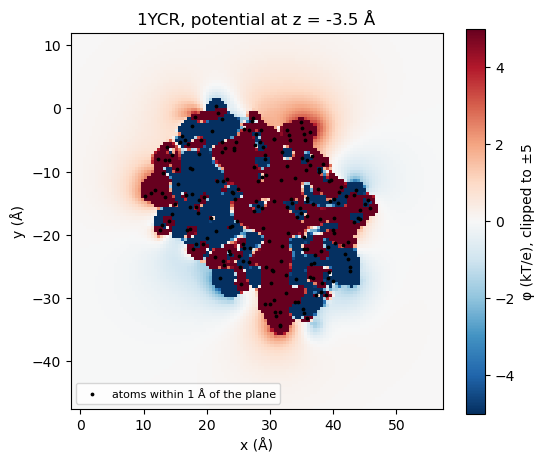

written: tutorial_output/1ycr_potential.dx


In [18]:
pot, origin, spacing, energy_kt = solver.potential(coords, charges, radii)
print("grid", pot.shape, "origin", np.round(origin, 2), "spacing", np.round(spacing, 3))

k = pot.shape[2] // 2
z = origin[2] + k * spacing[2]
x = origin[0] + spacing[0] * np.arange(pot.shape[0])
y = origin[1] + spacing[1] * np.arange(pot.shape[1])
near = np.abs(coords[:, 2] - z) < 1.0

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(x, y, pot[:, :, k].T, cmap="RdBu_r", vmin=-5, vmax=5, shading="auto")
ax.scatter(coords[near, 0], coords[near, 1], s=3, c="k", label="atoms within 1 Å of the plane")
ax.set(xlabel="x (Å)", ylabel="y (Å)", title=f"1YCR, potential at z = {z:.1f} Å", aspect="equal")
ax.legend(loc="lower left", fontsize=8)
fig.colorbar(im, label="φ (kT/e), clipped to ±5")
plt.show()

pbsolve.write_dx(OUT / "1ycr_potential.dx", pot, origin, spacing)
print("written:", OUT / "1ycr_potential.dx")

Inside the protein (ε = 1) the potential is large next to the charges, so the
colour scale saturates there. Outside, water and salt screen it: it decays
within a few Debye lengths (7.9 Å at 0.15 M), and the net charge of +3 e
leaves a mostly positive potential around the complex.

## 9. Reading simulation files and selecting atoms
_Last updated: 2026-11-06 (commit 7f2f939)._

`pbsolve.io.load` reads structures and topologies (PDB, PQR, mmCIF, GRO,
mol2, Amber prmtop, CHARMM/NAMD PSF, GROMACS top) into a `Molecule` with
names, residues, chains, charges, radii and coordinates. Selections use
`resname`, `name`, `resid`, `chain`, `element`, `protein`, `water`, `ions`,
`hydrogen` with `and`/`or`/`not`.

In [19]:
mol = pbsolve.io.load(PQR)
print(mol.n_atoms, "atoms | charges:", mol.has_charges, "| radii:", mol.has_radii)

peptide = mol.select("chain B")  # boolean mask
print("chain B:", peptide.sum(), "atoms, residues", mol.resids[peptide].min(), "to", mol.resids[peptide].max())
print("protein heavy atoms:", mol.select("protein and not hydrogen").sum())

mol.subset("chain B").write_pqr(OUT / "p53_peptide.pqr")
print("written:", OUT / "p53_peptide.pqr")

1670 atoms | charges: True | radii: True
chain B: 221 atoms, residues 17 to 29
protein heavy atoms: 819
written: tutorial_output/p53_peptide.pqr


Trajectories (DCD, XTC, TRR, Amber NetCDF, mdcrd, multi-model PDB/GRO) are
read frame by frame with `pbsolve.io.frames`. The repository's test files
are a small synthetic system:

In [20]:
system = pbsolve.io.load(DATA / "synthetic.gro")
for i, xyz in enumerate(pbsolve.io.frames(system, DATA / "synthetic.xtc")):
    print(f"frame {i}: {xyz.shape[0]} atoms, centre of geometry {np.round(xyz.mean(axis=0), 2)} Å")

frame 0: 40 atoms, centre of geometry [19.02 16.43 17.46] Å
frame 1: 40 atoms, centre of geometry [19.03 16.45 17.47] Å
frame 2: 40 atoms, centre of geometry [19.05 16.46 17.49] Å


## 10. Preparing a PDB file
_Last updated: 2026-11-06 (commit 7f2f939)._

A PDB file has no charges or radii. `pbsolve.prep.prepare` adds hydrogens,
rebuilds missing heavy atoms, optimises the hydrogen-bond network, assigns
protonation states and AMBER, PARSE or CHARMM parameters, following pdb2pqr.
For 1YCR it gives the same charges and radii as pdb2pqr 3:

In [21]:
prepared, report = pbsolve.prep.prepare(DATA / "1ycr.pdb", forcefield="amber")
print(report.summary())

same = np.array_equal(prepared.charges, charges) and np.array_equal(prepared.radii, radii)
print("\ncharges and radii identical to pdb2pqr:", same)
print(f"largest coordinate difference: {np.abs(prepared.coords - coords).max():.1e} Å (PQR files round to 0.001 Å)")

force field AMBER, protonation: standard states
1670 atoms (851 hydrogens added, 1 heavy atoms rebuilt), net charge +3.0000 e
states: HIS A73->HID, HIS A96->HID
hydrogen-bond optimisation: 3 flips (HIS A73, ASN A79, ASN A106)

charges and radii identical to pdb2pqr: True
largest coordinate difference: 5.0e-04 Å (PQR files round to 0.001 Å)


Use `ph=` for model-compound pKa rules, `titration="propka"` for PROPKA (if
installed) and `ligand="lig.mol2"` to append a ligand with its own charges.

## 11. MM-PBSA solvation terms
_Last updated: 2026-11-15 (interaction entropy)._

In single-trajectory MM-PBSA the receptor and the ligand are cut out of each
complex frame. `pbsa_solvation_frame` computes the polar (PB) and non-polar
(γ·SASA + β) solvation energies of complex, receptor and ligand on one shared
grid, so discretisation errors cancel in the difference. The binding free
energy adds the gas-phase term ΔE_MM from your force field:
ΔG_bind ≈ ΔE_MM + ΔG_solv.

In [22]:
ligand = np.nonzero(mol.select("chain B"))[0]  # the p53 peptide
frame = pbsolve.pbsa_solvation_frame(solver, coords, charges, radii, ligand_atoms=ligand)
show([[term, f"{value:.3f}"] for term, value in frame.as_dict().items()], ["term", "kcal/mol"])

| term | kcal/mol |
|---|---|
| complex_polar | -1231.348 |
| complex_nonpolar | 30.496 |
| receptor_polar | -1245.598 |
| receptor_nonpolar | 29.691 |
| ligand_polar | -409.446 |
| ligand_nonpolar | 10.242 |
| delta_polar | 423.695 |
| delta_nonpolar | -9.437 |
| delta_solvation | 414.258 |
| delta_reference | -361.431 |

**Per-residue shares.** Every term also comes per atom: atom i's polar
share is ½ q_i times the reaction field at the atom, the shares sum to
ΔG_polar exactly, and an interaction between two charges is split equally
between them; the non-polar share is γ·SASA_i (β belongs to no atom).
`atom_terms` gives every complex atom's share of the binding terms,
`residue_terms` their sums per residue. The five residues whose solvation
favours binding most and the three that oppose it most:


In [23]:
labels = [f"{c}:{n}:{i}" for c, n, i in zip(mol.chains, mol.resnames, mol.resids)]
shares = sorted(frame.residue_terms(labels).items(), key=lambda kv: sum(kv[1]))
show([[k, f"{p:.2f}", f"{n:.2f}"] for k, (p, n) in shares[:5] + shares[-3:]],
     ["residue", "polar share (kcal/mol)", "non-polar share (kcal/mol)"])
polar, nonpolar = frame.atom_terms()
print(f"polar shares sum to {polar.sum():.4f} kcal/mol, ΔG_polar of binding {frame.delta_polar:.4f}")


| residue | polar share (kcal/mol) | non-polar share (kcal/mol) |
|---|---|---|
| B:LYS:24 | -37.81 | -0.02 |
| A:VAL:109 | -30.61 | 0.00 |
| A:GLU:52 | -24.20 | 0.00 |
| A:GLU:95 | -22.35 | 0.00 |
| A:ASP:46 | -17.10 | 0.00 |
| A:LYS:51 | 55.62 | -0.27 |
| B:GLU:28 | 68.99 | -0.40 |
| B:ASN:29 | 89.20 | -0.77 |

polar shares sum to 423.6955 kcal/mol, ΔG_polar of binding 423.6955


Charged residues dominate both ends of the list. These are solvation
shares only: the Coulomb interaction across the interface, part of ΔE_MM
from the force field, offsets much of them, so a full per-residue picture
adds each residue's share of ΔE_MM. `pbsolve mmpbsa --per-residue FILE`
writes these shares averaged over a trajectory (`docs/guide/many.md`).


For a trajectory, `pbsa_solvation_frames` solves several calculations at a
time (default: 2 on the CPU, 3 on CUDA). The results do not depend on how
many run at once: they equal frame-by-frame results bit for bit.

On a GPU every calculation keeps its own buffers in device memory, about
130 bytes per grid node. pbsolve therefore runs no more calculations at once
than fit in the GPU memory that is free when the batch starts, also when you
pass `workers`. `solver.batch_workers(grid)` tells how many that is. Small
grids like this one get the default. On an 8 GB card with 6.3 GB free, two
calculations on a 19-million-node grid (a 20 000-atom protein) fit next to
each other, three do not.

Here, rigidly rotated and shifted copies of the complex stand in for MD
frames. They are the same structure, so the spread of ΔG_solv between them
is only the discretisation error of the grid:

In [24]:
def rigid_copy(xyz, rng):
    """xyz rotated about its centre by up to 10 degrees and shifted by up to 0.5 Å."""
    axis = rng.normal(size=3)
    axis /= np.linalg.norm(axis)
    angle = np.deg2rad(rng.uniform(-10, 10))
    k = np.array([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]])
    rot = np.eye(3) + np.sin(angle) * k + (1 - np.cos(angle)) * k @ k
    centre = xyz.mean(axis=0)
    return (xyz - centre) @ rot.T + centre + rng.uniform(-0.5, 0.5, size=3)


rng = np.random.default_rng(0)
frames = [rigid_copy(coords, rng) for _ in range(3)]
print(f"{solver.platform}: {solver.batch_workers(solver.make_grid(coords, radii))} calculations at once")

t0 = time.perf_counter()
together = pbsolve.pbsa_solvation_frames(solver, frames, charges, radii, ligand_atoms=ligand)
t_together = time.perf_counter() - t0
t0 = time.perf_counter()
one_by_one = [pbsolve.pbsa_solvation_frame(solver, f, charges, radii, ligand_atoms=ligand) for f in frames]
t_single = time.perf_counter() - t0

dg = np.array([f.delta_solvation for f in together])
print(f"ΔG_solv per frame: {np.round(dg, 3)} kcal/mol, mean {dg.mean():.3f} ± {dg.std(ddof=1) / np.sqrt(len(dg)):.3f}")
print(f"time: {t_together:.1f} s together, {t_single:.1f} s one by one")
print("identical results:", together == one_by_one)

CUDA: 3 calculations at once


ΔG_solv per frame: [414.952 416.323 414.979] kcal/mol, mean 415.418 ± 0.453
time: 1.5 s together, 1.9 s one by one
identical results: True


**Non-polar terms beyond the surface area.** `apolar_energy` computes the
model of APBS `apolar` (Wagoner & Baker 2006): γ·SASA, plus the solvent
pressure times the solvent-accessible volume (the cost of the cavity), plus
the attractive Lennard-Jones (WCA) interaction of every atom with the
solvent around it. It needs Lennard-Jones radii and well depths: from an
OpenMM system (`pbsolve.openmm_bridge.lennard_jones_from_system`, which also
covers Amber prmtop files) or from an APBS parameter file
(`pbsolve.apbs.read_parm`). APBS' own alkane examples, with the parameters
of Wagoner & Baker's alkane protocol:


In [25]:
from pbsolve.apbs import read_parm

alkanes = ROOT / "tests" / "data" / "apbs_alkanes"
parm = read_parm(alkanes / "parm.dat")  # (residue, atom) -> (charge, radius in Å, epsilon in kJ/mol)
rows = []
for name in ["methane", "ethane", "propane", "butane", "hexane", "cyclohexane"]:
    atoms = [f.split() for f in (alkanes / f"{name}.pdb").read_text().splitlines() if f.startswith(("ATOM", "HETATM"))]
    xyz = [[float(v) for v in a[5:8]] for a in atoms]
    lj = [parm[(a[3], a[2])] for a in atoms]
    g = pbsolve.apolar_energy(xyz, [p[1] for p in lj], [p[2] / 4.184 for p in lj], grid=0.3)
    rows.append([name, f"{g.area:.1f}", f"{g.surface:.3f}", f"{g.pressure_volume:.3f}", f"{g.dispersion:.3f}", f"{g.energy:.3f}"])
show(rows, ["alkane", "SASA (Å²)", "γ·SASA", "p·SAV", "dispersion", "total (kcal/mol)"])


| alkane | SASA (Å²) | γ·SASA | p·SAV | dispersion | total (kcal/mol) |
|---|---|---|---|---|---|
| methane | 105.4 | 0.214 | 5.492 | -3.819 | 1.887 |
| ethane | 139.4 | 0.283 | 8.030 | -6.061 | 2.252 |
| propane | 170.4 | 0.346 | 10.504 | -8.000 | 2.850 |
| butane | 193.9 | 0.394 | 12.466 | -9.971 | 2.888 |
| hexane | 250.3 | 0.508 | 17.054 | -13.643 | 3.920 |
| cyclohexane | 221.8 | 0.451 | 15.302 | -12.517 | 3.236 |

These are APBS' results for its alkane example to every digit it prints.
The volume and dispersion terms are an order of magnitude larger than the
area term and largely cancel. For 1YCR (1670 atoms) the same calculation
takes under a second on the CPU. The default γ·SASA + β of the MM-PBSA
functions above is unchanged; the parameters of this model were fitted to
alkanes, so use it for comparisons and studies of the non-polar term rather
than as a drop-in for proteins (`docs/guide/model.md`, *Non-polar term*).


**Binding entropy.** The terms above leave out the entropy of binding,
−TΔS. The interaction entropy (Duan, Liu & Zhang 2016) takes it from the
fluctuations of the gas-phase receptor–ligand interaction energy E_int over
the frames, −TΔS = kT ln⟨exp(β(E_int − ⟨E_int⟩))⟩; its second-order cumulant
(C2) is σ²/(2kT), with σ the standard deviation of E_int.
`interaction_energy` computes E_int (Coulomb plus Lennard-Jones; a PQR file
has no Lennard-Jones parameters, so only the Coulomb part here) and
`interaction_entropy` both estimates. Normally distributed stand-ins for the
E_int of 5000 frames show the catch: the exponential average is dominated by
a few frames and comes out too low as σ grows.

In [26]:
n = len(charges)
coulomb, _ = pbsolve.interaction_energy(coords, charges, np.zeros(n), np.zeros(n), ligand)
print(f"Coulomb interaction of MDM2 and p53 in vacuum: {coulomb:.1f} kcal/mol")

kt = pbsolve.kt_kcal_per_mol(298.15)
rows = []
for sigma in [0.5, 1.0, 2.0, 4.0]:
    e_int = np.random.default_rng(1).normal(coulomb, sigma, 5000)  # stand-ins for 5000 frames
    s = pbsolve.interaction_entropy(e_int, temperature=298.15)
    rows.append([f"{sigma:.1f}", f"{sigma**2 / (2 * kt):.2f}", f"{s.ie:.2f} ± {s.ie_sem:.2f}",
                 f"{s.c2:.2f} ± {s.c2_sem:.2f}", "yes" if s.reliable else "no"])
show(rows, ["σ (kcal/mol)", "exact −TΔS", "IE", "C2", "IE usable"])

Coulomb interaction of MDM2 and p53 in vacuum: -360.9 kcal/mol


| σ (kcal/mol) | exact −TΔS | IE | C2 | IE usable |
|---|---|---|---|---|
| 0.5 | 0.21 | 0.22 ± 0.01 | 0.21 ± 0.00 | yes |
| 1.0 | 0.84 | 0.89 ± 0.04 | 0.84 ± 0.02 | yes |
| 2.0 | 3.38 | 3.61 ± 0.21 | 3.38 ± 0.07 | yes |
| 4.0 | 13.50 | 11.02 ± 0.62 | 13.52 ± 0.29 | no |

Ekberg & Ryde (2021) found IE impossible to converge above σ = 15 kJ/mol
(3.6 kcal/mol) and recommend C2 where the two differ; the result therefore
carries σ, both estimates with their standard errors over blocks of frames,
and `reliable`. With a real trajectory, take the charges and Lennard-Jones
parameters from the OpenMM system (`pbsolve.openmm_bridge.charges_from_system`,
`lennard_jones_from_system`) and compute E_int frame by frame
(`docs/guide/many.md`, *Binding entropy*).

## 12. Checking against APBS
_Last updated: 2026-11-15 (forces)._

`pbsolve apbs compare` runs pbsolve and APBS on the same PQR file with the
same settings and compares grids, maps and energies (complex, receptor and
ligand, and the binding difference). It needs the `apbs` program.

APBS mixes CGS units with CODATA-1986 constants, while pbsolve uses CODATA
2018, so all energies differ by a constant factor (relative 1.2e-5). The
"APBS units" columns remove that factor. What remains is the solver
tolerance and, in the reference states, APBS' constants for the analytic
boundary (a few 1e-8 here).

In [27]:
apbs = shutil.which("apbs") or shutil.which("apbs", path=str(Path(sys.executable).parent))
if apbs:
    with tempfile.TemporaryDirectory() as work:  # APBS writes ~170 MB of potential maps
        cli("apbs", "compare", PQR, "--ionic-strength", 0.15, "--ligand-chain", "B",
            "--no-maps", "--apbs", apbs, "--workdir", work)
else:
    print("APBS not found; install it with: conda install -c conda-forge apbs")

[complex]
pbsolve vs APBS — /tmp/tmp_73c8a7y/complex/complex.pqr  (pbsolve on CUDA, files in /tmp/tmp_73c8a7y/complex)
  grid: dime [129, 129, 129], fine h = [0.4559, 0.4612, 0.3837] Å, 2 level(s): IDENTICAL
  energies (kJ/mol):          APBS         pbsolve     rel. diff   (APBS units)
    solvated            334051.4047    334047.3338   -1.22e-05   -4.17e-12
    reference           339161.2462    339157.1155   -1.22e-05   +7.39e-09
  ΔG_polar (kcal/mol): APBS -1221.2814   pbsolve -1221.2671   diff +0.0143 (+0.0012 %; -0.0000 % in APBS units)
  verdict: PASS

[receptor]
pbsolve vs APBS — /tmp/tmp_73c8a7y/receptor/receptor.pqr  (pbsolve on CUDA, files in /tmp/tmp_73c8a7y/receptor)
  grid: dime [129, 129, 129], fine h = [0.4559, 0.4612, 0.3837] Å, 2 level(s): IDENTICAL
  energies (kJ/mol):          APBS         pbsolve     rel. diff   (APBS units)
    solvated            284199.8845    284196.4211   -1.22e-05   -3.34e-11
    reference           289362.9593    289359.4395   -1.22e-05   +

The binding verdict asks for ΔΔG_polar within 0.05 kcal/mol in APBS units.
The same agreement holds for larger proteins (`docs/VALIDATION.md`, *APBS
parity: larger proteins*). For HIV-1 protease (1HPV), an AB5 toxin (1TII) and
an antibody (5DK3, 20 179 atoms), ΔG_polar agrees within 4e-6 in APBS units
and ΔΔG_polar within 0.042 kcal/mol; the maps of 1HPV and 1TII are identical.

`pbsolve apbs run input.in` evaluates an existing APBS input file with
pbsolve (and APBS, if installed). Both commands take `--preconditioner`, and
`compare` takes `--bcfl mdh-fast`, to check the optional methods against
APBS. APBS' B-spline charges (`chgm spl2`, `spl4`; `--chgm` and
`Solver(chgm=...)` in pbsolve) are reproduced as well, with identical maps
and energies within the same few parts per million. So is the nonlinear
equation (`npbe`; `--equation npbe`): APBS' Newton solution and free-energy
functional, with solvated energies within a few 1e-9 in APBS units. The
size-modified equation (`smpbe`) cannot be compared: APBS 3.4.1 disables it.
With a spline surface, `--forces` also compares the per-atom forces
(`calcforce comps`): they agree to a few parts in 10⁷ of the largest force.

## 13. Command line
_Last updated: 2026-11-06 (commit 7f2f939)._

Everything above is also available from the shell:

| Command | Purpose |
|---|---|
| `pbsolve info`, `pbsolve test` | installation status and check |
| `pbsolve solvation FILE` | polar + non-polar solvation energy (`--dx` writes the potential) |
| `pbsolve convert FILE out.pqr` | any supported input to PQR (`--select`, `--radii`) |
| `pbsolve prep in.pdb out.pqr` | structure preparation (`--ff`, `--ph`, `--titration propka`) |
| `pbsolve mmpbsa TOP TRAJ --ligand SEL` | MM-PBSA solvation terms along a trajectory (`--csv`) |
| `pbsolve apbs compare/run` | comparison with APBS |

In [28]:
cli("solvation", PQR, "--ionic-strength", 0.15)

              file: ../tests/data/1ycr_amber_opt_pdb2pqr.pqr
             atoms: 1670
        net_charge: 3.0000000000000036
    polar_kcal_mol: -1231.34813592155
 nonpolar_kcal_mol: 30.495710415544938
          platform: CUDA
            device: NVIDIA GeForce RTX 2080 SUPER (cc 7.5, device 0)
     cg_iterations: [12, 12, 8, 8]
    preconditioner: ['multigrid-f32']
  multigrid_levels: [5, 5, 5, 5]
              dime: [121, 121, 105]
      fine_spacing: [0.4863416666666667, 0.49196833333333334, 0.4722307692307692]


## 14. Further reading
_Last updated: 2026-11-15 (atom dielectrics)._

* `docs/guide/`: the user guide, topic by topic (physical model, grids,
  solver, CPU and GPU, MM-PBSA, input files, command line, APBS comparison).
* `docs/VALIDATION.md`: every check behind the numbers above (analytic
  references, APBS parity, precision, timings).
* `docs/ARCHITECTURE.md`: the equations, discretisation and code layout.
* `docs/ROADMAP.md`: planned work. On an idle GPU the fused solver steps
  make a calculation 1.09–1.12× faster; with the default boundary the
  host's `mdh` sum is now half of a large CUDA calculation. Accuracy (v0.2):
  B-spline charges, analytic references, error estimates, the
  fractional interface and the reaction-field decomposition are done.
  Physics (v0.3): the nonlinear equation, ions of finite size, APBS-style forces and the
  Gaussian dielectric are done. End-point free energies (v0.4): the non-polar model of
  APBS `apolar`, per-residue shares, the interaction entropy and atom
  dielectrics are done.
* `examples/mmpbsa_openmm.py`: PB solvation inside an OpenMM workflow.
* `help(pbsolve.Solver)`, `help(pbsolve.Solver.polar_solvation)` and so on:
  parameters, units, return values and errors of every class and function.
  The same text is the API reference of the documentation site (`docs/`,
  to be published with the first public release).